# 02 · Feature Engineering
**Project 1: Rossmann Store Sales Prediction**

## Objective
- Create date features (year, month, day, day of week, week of year, is_weekend, is_month_end)
- Create lag features, and check which lags are really usable for a **6-week-ahead** forecast
- One-hot encode categoricals (`store_type`, `state_holiday`) inside a Pipeline
- Use a correlation heatmap to drop highly correlated pairs (|r| > 0.9)
- Check, with a quick model, whether the new features actually help

> **Data:** the real Rossmann Store Sales data (`train.csv`, `store.csv`), same as notebook 01.
> The files are not in this repo (competition data rules). The notebook uses `data/` if the files are there,
> otherwise it downloads them from a public copy. See `data/README.md`.

## Project setup

In [1]:
import sys
from pathlib import Path

# Project folders (works from notebooks/ or from the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"
OUT = ROOT / "outputs"
FIG = OUT / "features"
FIG.mkdir(parents=True, exist_ok=True)

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor

## Reminder from notebook 01
- Target: `Sales` per store per day. Metric: **RMSPE**. Validation: the **last 42 days** (a 6-week forecast)
- `Customers` is a leak, so it is not used
- Baseline to beat: **RMSPE 0.147** (store + weekday + promo average)

In [3]:
BASE = "https://raw.githubusercontent.com/RPI-DATA/tutorials-intro/master/rossmann-store-sales/rossmann-store-sales/"

def load(name):
    local = DATA / name
    return pd.read_csv(local if local.exists() else BASE + name, low_memory=False)

train = load("train.csv")
store = load("store.csv")
train["Date"] = pd.to_datetime(train["Date"])
train = train.sort_values(["Store", "Date"]).reset_index(drop=True)
print(train.shape, store.shape)

(1017209, 9) (1115, 10)


## 1. Feature functions (saved to `features.py` so notebook 03 can reuse them)
Writing the steps as functions keeps the work repeatable and makes sure train and test data get the exact same treatment.

The functions live in `src/features.py` (printed below), so every notebook uses exactly the same code.

In [4]:
print((ROOT / "src" / "features.py").read_text())

import numpy as np
import pandas as pd


def add_date_features(df):
    """Calendar features from the Date column."""
    out = df.copy()
    d = out["Date"]
    out["year"] = d.dt.year
    out["month"] = d.dt.month
    out["day"] = d.dt.day
    out["day_of_week"] = d.dt.dayofweek            # 0 = Monday ... 6 = Sunday
    out["week_of_year"] = d.dt.isocalendar().week.astype(int)
    out["is_weekend"] = (d.dt.dayofweek >= 5).astype(int)
    out["is_month_end"] = d.dt.is_month_end.astype(int)
    return out


def add_lag_features(df, lags=(1, 7, 42, 49), target="Sales"):
    """Sales k days ago for the same store, matched by DATE (not by row position).

    Some stores have missing dates, so shifting rows would pick the wrong day.
    """
    out = df.copy()
    s = out.set_index(["Store", "Date"])[target]
    for k in lags:
        keys = pd.MultiIndex.from_arrays([out["Store"], out["Date"] - pd.Timedelta(days=k)])
        out["lag_" + str(k)] = s.reindex(keys).to_numpy()
    return ou

In [5]:
from features import add_date_features, add_lag_features, merge_store_info, add_store_history

feat = add_date_features(train)
feat = add_lag_features(feat, lags=(1, 7, 42, 49))
feat = merge_store_info(feat, store)
feat["state_holiday"] = feat["state_holiday"].astype(str)
print(feat.shape)

(1017209, 24)


## 2. Date features

In [6]:
date_cols = ["Date", "month", "day", "day_of_week", "week_of_year", "is_weekend", "is_month_end"]
print(feat[date_cols].tail(3))

              Date  month  day  day_of_week  week_of_year  is_weekend  \
1017206 2015-07-29      7   29            2            31           0   
1017207 2015-07-30      7   30            3            31           0   
1017208 2015-07-31      7   31            4            31           0   

         is_month_end  
1017206             0  
1017207             0  
1017208             1  


## 3. Lag features

In [7]:
# Work on open days only (as in notebook 01)
open_feat = feat[(feat["Open"] == 1) & (feat["Sales"] > 0)].copy()

lag_cols = ["lag_1", "lag_7", "lag_42", "lag_49"]
corr_with_sales = open_feat[["Sales"] + lag_cols].corr()["Sales"].drop("Sales").round(3)
print("Correlation of Sales with each lag (open days):")
print(corr_with_sales)

Correlation of Sales with each lag (open days):
lag_1     0.392
lag_7     0.556
lag_42    0.674
lag_49    0.620
Name: Sales, dtype: float64


In [8]:
# Why is lag_42 more correlated than lag_7? Check lags that landed on a closed day (sales = 0)
for k in [1, 7, 42, 49]:
    nz = open_feat[open_feat["lag_" + str(k)] > 0]
    share_zero = (open_feat["lag_" + str(k)] == 0).mean() * 100
    print(f"lag_{k:<2d}: lag day was closed (0 sales) for {share_zero:4.1f}% of rows | r without those rows = {nz['Sales'].corr(nz['lag_' + str(k)]):.3f}")

lag_1 : lag day was closed (0 sales) for 19.1% of rows | r without those rows = 0.869
lag_7 : lag day was closed (0 sales) for  3.4% of rows | r without those rows = 0.627


lag_42: lag day was closed (0 sales) for  3.7% of rows | r without those rows = 0.750


lag_49: lag day was closed (0 sales) for  3.2% of rows | r without those rows = 0.680


### Why are some lags much better than others?
`lag_7` (r = 0.627) is *weaker* than `lag_42` (r = 0.750). A guess: promotions run in alternating weeks for many stores,
so a lag of an **even** number of weeks shares today's promo status and an **odd** number of weeks does not. Let's test it.

In [9]:
lags_w = (7, 14, 28, 35, 42, 49, 56)
sales_lags = add_lag_features(feat[["Store", "Date", "Sales", "Open"]], lags=lags_w, target="Sales")
promo_lags = add_lag_features(feat[["Store", "Date", "Promo"]], lags=lags_w, target="Promo")
is_open = (sales_lags["Open"] == 1) & (sales_lags["Sales"] > 0)

for k in lags_w:
    col = "lag_" + str(k)
    ok = is_open & (sales_lags[col] > 0)
    r = sales_lags.loc[ok, "Sales"].corr(sales_lags.loc[ok, col])
    pl = promo_lags.loc[is_open, col]
    has_value = pl.notna()
    same = (pl[has_value] == feat.loc[is_open, "Promo"][has_value]).mean() * 100
    print(f"lag_{k:<2d} ({k // 7} weeks): r = {r:.3f} | promo same as today: {same:.1f}%")

lag_7  (1 weeks): r = 0.627 | promo same as today: 25.1%
lag_14 (2 weeks): r = 0.832 | promo same as today: 84.7%
lag_28 (4 weeks): r = 0.794 | promo same as today: 73.4%
lag_35 (5 weeks): r = 0.666 | promo same as today: 47.8%
lag_42 (6 weeks): r = 0.750 | promo same as today: 68.6%


lag_49 (7 weeks): r = 0.680 | promo same as today: 51.5%
lag_56 (8 weeks): r = 0.717 | promo same as today: 62.6%


**Result:** the promo status matches today's only 25% of the time one week ago, but 85% of the time two weeks ago.
Even-week lags (14, 28, 42, 56) are better than odd-week lags (7, 35, 49). Under a 42-day horizon, `lag_42` is the closest usable even-week lag.

### Which lags can we really use?
We forecast **6 weeks ahead**. When we make the forecast (the day before the validation window starts), we do not know any sales inside the window.
So a lag of `k` days is only usable for a given date if that earlier day is **before** the forecast starts.

In [10]:
cut = train["Date"].max() - pd.Timedelta(days=41)     # first validation day
valid_rows = open_feat[open_feat["Date"] >= cut]

print("Validation window starts:", cut.date(), "(42 days)")
for k in [1, 7, 42, 49]:
    known = ((valid_rows["Date"] - pd.Timedelta(days=k)) < cut).mean() * 100
    print(f"lag_{k:<2d} is known at forecast time for {known:5.1f}% of validation rows")

Validation window starts: 2015-06-20 (42 days)
lag_1  is known at forecast time for   2.8% of validation rows
lag_7  is known at forecast time for  16.7% of validation rows
lag_42 is known at forecast time for 100.0% of validation rows
lag_49 is known at forecast time for 100.0% of validation rows


**Takeaway:** `lag_1` and `lag_7` look natural, but at a 6-week horizon they are mostly unknown. `lag_42` and `lag_49` are always known.
We keep `lag_42` and `lag_49` as the safe lags. Below, a quick experiment shows what happens if we cheat with `lag_1` and `lag_7`.

## 4. Encode categoricals with OneHotEncoder inside a Pipeline

In [11]:
cat_cols = ["store_type", "assortment", "state_holiday"]
print(open_feat[cat_cols].apply(lambda s: sorted(s.unique())).to_string())

store_type       [a, b, c, d]
assortment          [a, b, c]
state_holiday    [0, a, b, c]


In [12]:
past = open_feat[open_feat["Date"] < cut]      # fit encoders on the past only
valid = open_feat[open_feat["Date"] >= cut]

encoder = ColumnTransformer(
    [("onehot", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cat_cols)],
    remainder="passthrough",
)
encoder.fit(past[cat_cols + ["Promo"]])
encoded = encoder.transform(past[cat_cols + ["Promo"]])

print("Before:", past[cat_cols + ["Promo"]].shape)
print("After: ", encoded.shape)
print(list(encoder.get_feature_names_out()))

Before: (804056, 4)
After:  (804056, 12)
['onehot__store_type_a', 'onehot__store_type_b', 'onehot__store_type_c', 'onehot__store_type_d', 'onehot__assortment_a', 'onehot__assortment_b', 'onehot__assortment_c', 'onehot__state_holiday_0', 'onehot__state_holiday_a', 'onehot__state_holiday_b', 'onehot__state_holiday_c', 'remainder__Promo']


## 5. Correlation heatmap and dropping pairs with |r| > 0.9

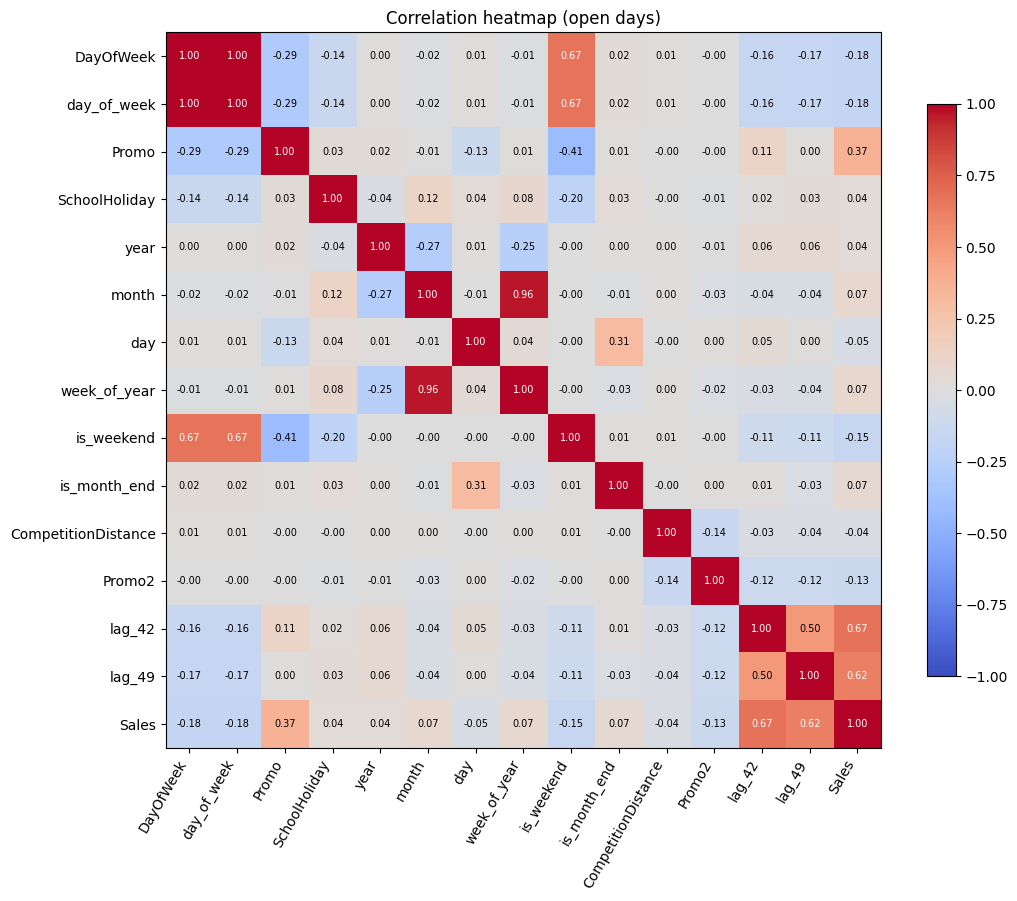

In [13]:
heat_cols = ["DayOfWeek", "day_of_week", "Promo", "SchoolHoliday", "year", "month", "day",
             "week_of_year", "is_weekend", "is_month_end", "CompetitionDistance", "Promo2",
             "lag_42", "lag_49"]
corr = open_feat[heat_cols + ["Sales"]].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation heatmap (open days)")
plt.tight_layout()
plt.savefig(FIG / "correlation_heatmap.png", dpi=150)
plt.show()

In [14]:
# Find pairs with |r| > 0.9 (features only, not the target)
feat_corr = corr.drop(index="Sales", columns="Sales").abs()
target_corr = corr["Sales"].abs()

pairs, dropped = [], set()
for i, a in enumerate(feat_corr.columns):
    for b in feat_corr.columns[i + 1:]:
        if feat_corr.loc[a, b] > 0.9:
            # keep the feature that is more related to Sales, drop the other
            drop = a if target_corr[a] < target_corr[b] else b
            pairs.append((a, b, round(corr.loc[a, b], 3), drop))
            dropped.add(drop)

for a, b, r, drop in pairs:
    print(f"{a} vs {b}: r = {r} -> drop {drop}")
print("Dropped:", sorted(dropped))

DayOfWeek vs day_of_week: r = 1.0 -> drop day_of_week
month vs week_of_year: r = 0.961 -> drop month
Dropped: ['day_of_week', 'month']


In [15]:
kept_numeric = [c for c in heat_cols if c not in dropped]
print("Kept numeric features:", kept_numeric)

Kept numeric features: ['DayOfWeek', 'Promo', 'SchoolHoliday', 'year', 'day', 'week_of_year', 'is_weekend', 'is_month_end', 'CompetitionDistance', 'Promo2', 'lag_42', 'lag_49']


## 6. Quick check: do the new features actually help?

A fast gradient boosting model (`HistGradientBoostingRegressor`) on `log(1 + Sales)`, scored with RMSPE on the 42-day validation window.
This is only a check, the full model work is notebook 03. Four feature sets:
- **A:** the raw columns only
- **B:** A + date features + store info + the safe lags (`lag_42`, `lag_49`)
- **C:** B after dropping the highly correlated features
- **D (cheating):** B + `lag_1` + `lag_7` taken from real validation sales, which would not exist at forecast time
- **E:** B + store history features (added after seeing the first results)

In [16]:
def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = y_true > 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

def score(numeric, categorical):
    pre = ColumnTransformer(
        [("onehot", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), categorical)],
        remainder="passthrough",
    )
    model = Pipeline([
        ("prep", pre),
        ("gbm", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42)),
    ])
    cols = numeric + categorical
    model.fit(past[cols], np.log1p(past["Sales"]))
    pred = np.expm1(model.predict(valid[cols]))
    return rmspe(valid["Sales"], pred)

raw_num = ["Store", "DayOfWeek", "Promo", "SchoolHoliday"]
raw_cat = ["state_holiday"]

new_num = raw_num + ["year", "month", "day", "week_of_year", "is_weekend", "is_month_end",
                     "CompetitionDistance", "Promo2", "lag_42", "lag_49"]
new_cat = raw_cat + ["store_type", "assortment"]

pruned_num = [c for c in new_num if c not in dropped]


In [17]:
results = {
    "A) raw columns only": score(raw_num, raw_cat),
    "B) + date, store, safe lags": score(new_num, new_cat),
    "C) B without correlated pairs": score(pruned_num, new_cat),
    "D) B + lag_1, lag_7 (cheating)": score(new_num + ["lag_1", "lag_7"], new_cat),
}
for name, value in results.items():
    print(f"{name:32s} RMSPE = {value:.3f}")
print(f"{'plain-average baseline (store+day+promo)':32s} RMSPE = 0.147")

A) raw columns only              RMSPE = 0.364
B) + date, store, safe lags      RMSPE = 0.174
C) B without correlated pairs    RMSPE = 0.178
D) B + lag_1, lag_7 (cheating)   RMSPE = 0.131
plain-average baseline (store+day+promo) RMSPE = 0.147


### A missing ingredient: store history
Set B still has no memory of how big each store is (`Store` is just a number to the model).
The plain-average baseline had that built in. So we add two features learned **only from the past**:
`store_mean` and `store_dow_mean` (average sales for the store, and for the store on that weekday).

In [18]:
from features import add_store_history

past = add_store_history(past, history=past)
valid = add_store_history(valid, history=past)

history_num = new_num + ["store_mean", "store_dow_mean"]
results["E) B + store history"] = score(history_num, new_cat)
print(f"{'E) B + store history':32s} RMSPE = {results['E) B + store history']:.3f}")

E) B + store history             RMSPE = 0.148


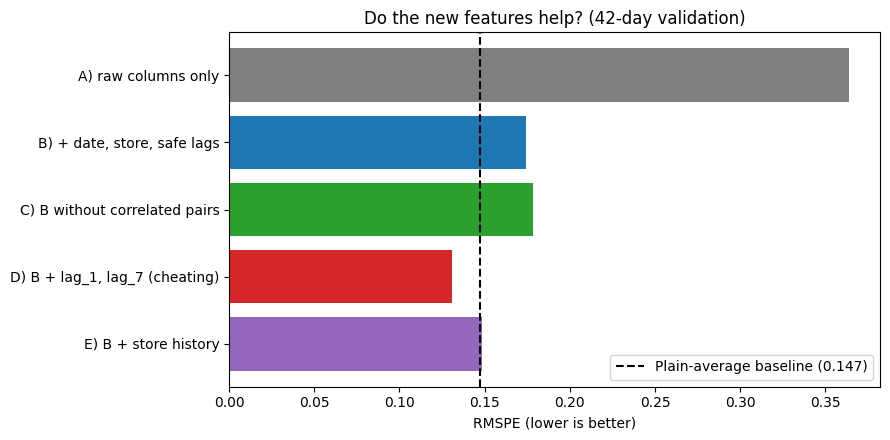

In [19]:
plt.figure(figsize=(9, 4.5))
names = list(results)
vals = [results[n] for n in names]
colors = ["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728", "#9467bd"]
plt.barh(names[::-1], vals[::-1], color=colors[::-1])
plt.axvline(0.147, color="black", linestyle="--", label="Plain-average baseline (0.147)")
plt.xlabel("RMSPE (lower is better)")
plt.title("Do the new features help? (42-day validation)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "feature_sets_rmspe.png", dpi=150)
plt.show()

## Practice Exercise
Build `lag_mean_42_56`: the average of `lag_42`, `lag_49`, and `lag_56` (same weekday, 6, 7 and 8 weeks ago). Is it more correlated with Sales than `lag_42` alone?

In [20]:
both = add_lag_features(feat[["Store", "Date", "Sales", "Open"]], lags=(42, 49, 56))
both["lag_mean_42_56"] = both[["lag_42", "lag_49", "lag_56"]].mean(axis=1)
both = both[(both["Open"] == 1) & (both["Sales"] > 0)]
print("lag_42 alone:   ", round(both["Sales"].corr(both["lag_42"]), 3))
print("lag_mean_42_56: ", round(both["Sales"].corr(both["lag_mean_42_56"]), 3))

lag_42 alone:    0.674
lag_mean_42_56:  0.769


## Mini Challenge
Does `is_month_end` matter? Compare average sales on month-end days vs other days (open days).

In [21]:
print(open_feat.groupby("is_month_end")["Sales"].agg(["mean", "count"]).round(0))

                mean   count
is_month_end                
0             6918.0  816299
1             8069.0   28039


## Summary
- Date features, store info, and safe lags give the model more to work with than the raw columns
- Lags must respect the forecast horizon: for a 6-week forecast, only lags of 42 days or more are known
- OneHotEncoder fitted on the past only, inside a pipeline, keeps the process honest
- Dropping |r| > 0.9 pairs removes duplicate information
- A feature that looks great but is not available at forecast time gives a fake score (set D)
- Next: notebook 03, model training and evaluation